In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "16"
import warnings

warnings.filterwarnings("ignore", category=UserWarning, module="sklearn.cluster._kmeans")


In [2]:
import multiprocessing
print(multiprocessing.cpu_count())

16


In [3]:
# Standard library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Sklearn
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import KBinsDiscretizer, OneHotEncoder, StandardScaler
from sklearn.base import clone, is_classifier, is_regressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.svm import SVC
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import r2_score, accuracy_score, mean_absolute_error, mean_squared_error


wq_class_df = pd.read_csv("datasets/winequality-red.csv", delimiter=";")
wq_reg_df = pd.read_csv("datasets/winequality-red.csv", delimiter=";")
bc_df = pd.read_csv("datasets/Breast-Cancer-Wisconsin-(Diagnostic)-Data-Set.csv").drop(columns=["id"])
ch_df = pd.read_csv("datasets/california-housing-data.csv")
db_df = pd.read_excel("datasets/Dry_Bean_Dataset.xlsx")
asn_df = pd.read_csv("datasets/AirfoilSelfNoise.csv")


dataset_names = ["bc", "wq_class", "ch", "db", "asn", "wq_reg"]
dataset_dfs = [bc_df, wq_class_df, ch_df, db_df, asn_df, wq_reg_df]
datasets = dict(zip(dataset_names, dataset_dfs))
task_type = {"bc": "classification", "wq_class": "classification", "ch": "regression", "db": "classification", "asn": "regression", "wq_reg": "regression"}
pd.set_option("display.max_rows", 20)

datasets["db"]


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13606,42097,759.696,288.721612,185.944705,1.552728,0.765002,42508,231.515799,0.714574,0.990331,0.916603,0.801865,0.006858,0.001749,0.642988,0.998385,DERMASON
13607,42101,757.499,281.576392,190.713136,1.476439,0.735702,42494,231.526798,0.799943,0.990752,0.922015,0.822252,0.006688,0.001886,0.676099,0.998219,DERMASON
13608,42139,759.321,281.539928,191.187979,1.472582,0.734065,42569,231.631261,0.729932,0.989899,0.918424,0.822730,0.006681,0.001888,0.676884,0.996767,DERMASON
13609,42147,763.779,283.382636,190.275731,1.489326,0.741055,42667,231.653248,0.705389,0.987813,0.907906,0.817457,0.006724,0.001852,0.668237,0.995222,DERMASON


In [4]:
models = {
    "logreg": LogisticRegression(max_iter=10000), 
    "svc": SVC(), 
    "dt": DecisionTreeClassifier(), 
    "knc": KNeighborsClassifier(),
    "rfc": RandomForestClassifier(),
    "linreg": LinearRegression(),
    "dtr": DecisionTreeRegressor(),
    "knr": KNeighborsRegressor(),
    "rfr": RandomForestRegressor(n_jobs=16)
    }

trees = ["dt", "dtr", "rfc", "rfr"]

precision_values = {
    "rounding": [-2,-1,0,1,2,3], 
    "uniform": [2,3,4,5,6], 
    "quantile": [2,3,4,5,6], 
    "kmeans": [2,3,4,5,6], 
    "sig figs": [1,2,3,4,5,6]
    }

modes = ["both", "training_data_only", "testing_data_only"]

metrics = {
    "classification": {"accuracy": accuracy_score},
    "regression": {"mae": mean_absolute_error, "r2": r2_score, "mse": mean_squared_error}
}

In [5]:

def handle_missing(X):
    X = X.copy()

    num_cols = X.select_dtypes(include=["number"]).columns
    cat_cols = X.select_dtypes(exclude=["number"]).columns

    if len(num_cols) > 0:
        num_imp = SimpleImputer(strategy="median")
        X[num_cols] = num_imp.fit_transform(X[num_cols])

    if len(cat_cols) > 0:
        cat_imp = SimpleImputer(strategy="most_frequent")
        X[cat_cols] = cat_imp.fit_transform(X[cat_cols])

    return X

In [6]:

for name, dataset in datasets.items():

    if dataset.isna().any().any():
        datasets[name] = handle_missing(dataset)

datasets["db"].isna().sum().sum()

np.int64(0)

In [7]:
target_columns = {
    "bc": "diagnosis",
    "wq_class": "quality", 
    "ch": "median_house_value",
    "db": "Class",
    "asn": "SSPL",
    "wq_reg": "quality"
}

X = {}
for name in dataset_names:
    X[name] = datasets[name].drop(columns=[target_columns[name]])

y = {}
for name in dataset_names:
    y[name] = datasets[name][target_columns[name]]

X["asn"]


,f,alpha,c,U_infinity,delta
0,800,0.0,0.3048,71.3,0.002663
1,1000,0.0,0.3048,71.3,0.002663
2,1250,0.0,0.3048,71.3,0.002663
3,1600,0.0,0.3048,71.3,0.002663
4,2000,0.0,0.3048,71.3,0.002663
...,...,...,...,...,...
1498,2500,15.6,0.1016,39.6,0.052849
1499,3150,15.6,0.1016,39.6,0.052849
1500,4000,15.6,0.1016,39.6,0.052849
1501,5000,15.6,0.1016,39.6,0.052849


In [8]:
def sig_fig_round(num, sig):

    if pd.isna(num):
        return num

    if not isinstance(num, (int, float, np.floating, np.integer)):
        return num

    if num == 0:
        return 0
    
    return np.round(num, sig - int(np.floor(np.log10(abs(num)))) - 1)


In [9]:
# sig_fig_round("4.2212",1)

In [10]:
splits = {}
random_state = 42
for name in X:
    X_train, X_test, y_train, y_test = train_test_split(
        X[name], y[name], train_size=0.8, random_state=random_state
    )
    
    splits[name] = {
        "X_train": X_train,
        "X_test": X_test,
        "y_train": y_train,
        "y_test": y_test
    }
splits["wq_reg"]["X_train"]

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
493,8.7,0.690,0.31,3.0,0.086,23.0,81.0,1.00020,3.48,0.74,11.6
354,6.1,0.210,0.40,1.4,0.066,40.5,165.0,0.99120,3.25,0.59,11.9
342,10.9,0.390,0.47,1.8,0.118,6.0,14.0,0.99820,3.30,0.75,9.8
834,8.8,0.685,0.26,1.6,0.088,16.0,23.0,0.99694,3.32,0.47,9.4
705,8.4,1.035,0.15,6.0,0.073,11.0,54.0,0.99900,3.37,0.49,9.9
...,...,...,...,...,...,...,...,...,...,...,...
1130,9.1,0.600,0.00,1.9,0.058,5.0,10.0,0.99770,3.18,0.63,10.4
1294,8.2,0.635,0.10,2.1,0.073,25.0,60.0,0.99638,3.29,0.75,10.9
860,7.2,0.620,0.06,2.7,0.077,15.0,85.0,0.99746,3.51,0.54,9.5
1459,7.9,0.200,0.35,1.7,0.054,7.0,15.0,0.99458,3.32,0.80,11.9


In [11]:

def encode_categorical(X_train, X_test, model_name):


    cat_cols = X_train.select_dtypes(include=["object", "category"]).columns

    if len(cat_cols) == 0:
        return X_train.copy(), X_test.copy()

    if model_name not in trees:
        encoder = OneHotEncoder(drop="first")
    else:
        encoder = OneHotEncoder(drop=None)
    encoder.fit(X_train[cat_cols])

    train_cat = encoder.transform(X_train[cat_cols]).toarray()
    test_cat = encoder.transform(X_test[cat_cols]).toarray()

    new_col_names = encoder.get_feature_names_out(cat_cols)

    train_cat_df = pd.DataFrame(train_cat, columns=new_col_names, index=X_train.index)
    test_cat_df = pd.DataFrame(test_cat, columns=new_col_names, index=X_test.index)

    # print(train_cat_df)

    X_train_num = X_train.drop(columns=cat_cols)
    X_test_num = X_test.drop(columns=cat_cols)

    X_train_enc = pd.concat([X_train_num, train_cat_df], axis=1)
    X_test_enc = pd.concat([X_test_num, test_cat_df], axis=1)

    return X_train_enc, X_test_enc

In [12]:
# encode_categorical(datasets["le"], datasets["le"], "linreg")[0]


In [13]:
# encode_categorical(splits["ch"]["X_train"], splits["ch"]["X_train"], "dt")


In [14]:
def apply_transformation(X_train, X_test, method, level, mode):

    if mode not in ["both", "training_data_only", "testing_data_only"]:
        raise ValueError(f"Unknown mode: {mode}.")
    
    X_train_new, X_test_new = X_train.copy(), X_test.copy()
    
    if method == "rounding":

        if mode == "both" or mode == "training_data_only":
            X_train_new = X_train_new.round(level)
        if mode == "both" or mode == "testing_data_only":
            X_test_new = X_test_new.round(level)
            
    elif method in ["uniform", "quantile", "kmeans"]:

        if level < 2:
            raise ValueError(f"Number of bins out of range: {level}.")

        for col in X_train.columns:

            if not pd.api.types.is_numeric_dtype(X_train[col]):
                continue

            if X_train_new[col].nunique() < level:
                continue
            
            if method == "quantile":
                kbd = KBinsDiscretizer(n_bins=level, encode="ordinal", strategy=method, quantile_method="linear")
            else:
                kbd = KBinsDiscretizer(n_bins=level, encode="ordinal", strategy=method)

            kbd.fit(X_train_new[[col]])

            if mode in ["both", "training_data_only"]:
                X_train_new[col] = kbd.inverse_transform(kbd.transform(X_train_new[[col]])).ravel()

            if mode in ["both", "testing_data_only"]:
                X_test_new[col] = kbd.inverse_transform(kbd.transform(X_test_new[[col]])).ravel()

           
    elif method == "sig figs":

        if level < 1:
            raise ValueError(f"Number of significant figures out of range: {level}.")
        
        if mode == "both" or mode == "training_data_only":
            cols = X_train_new.select_dtypes(include=[np.number]).columns
            X_train_new[cols] = X_train_new[cols].map(lambda x: sig_fig_round(x, level))
        if mode == "both" or mode == "testing_data_only":
            cols = X_test_new.select_dtypes(include=[np.number]).columns
            X_test_new[cols] = X_test_new[cols].map(lambda x: sig_fig_round(x, level))

    else:
        raise ValueError(f"Unknown method: {method}.")
            
    return X_train_new, X_test_new

In [15]:

def standard_scale(X_train, X_test):
    X_train_scaled = X_train.copy()
    X_test_scaled = X_test.copy()

    numeric_cols = X_train_scaled.select_dtypes(include=[np.number]).columns
    if len(numeric_cols) == 0:
        return X_train_scaled, X_test_scaled

    scaler = StandardScaler()
    X_train_scaled[numeric_cols] = scaler.fit_transform(X_train_scaled[numeric_cols])
    X_test_scaled[numeric_cols] = scaler.transform(X_test_scaled[numeric_cols])

    return X_train_scaled, X_test_scaled

In [16]:
standard_scale(splits["ch"]["X_train"], splits["ch"]["X_test"])[0]


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity
14196,1.272587,-1.372811,0.348490,0.222569,0.211228,0.768276,0.322906,-0.326196,NEAR OCEAN
8267,0.709162,-0.876696,1.618118,0.340293,0.593094,-0.098901,0.672027,-0.035843,NEAR OCEAN
17445,-0.447603,-0.460146,-1.952710,-0.342597,-0.495226,-0.449818,-0.430461,0.144701,NEAR OCEAN
14265,1.232698,-1.382172,0.586545,-0.561490,-0.409306,-0.007434,-0.380587,-1.017864,NEAR OCEAN
2271,-0.108551,0.532084,1.142008,-0.119565,-0.256559,-0.485877,-0.314962,-0.171488,INLAND
...,...,...,...,...,...,...,...,...,...
11284,0.808883,-0.872016,0.507194,-0.603337,-0.805492,-0.675847,-0.742833,1.307215,<1H OCEAN
11964,1.073144,-0.759688,0.348490,0.203255,0.075188,0.287195,-0.133839,-0.436266,INLAND
5390,0.599469,-0.755007,0.586545,-0.248786,0.072801,0.289833,0.070909,-0.496973,<1H OCEAN
860,-1.185540,0.906510,-1.079841,0.429046,0.139628,0.308303,0.154908,0.965450,<1H OCEAN


In [17]:
apply_transformation(splits["wq_reg"]["X_train"], splits["wq_reg"]["X_test"], "quantile", 2, "both")[0]

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
493,11.90,1.05,0.63,8.85,0.3455,41.0,163.5,1.000245,3.660,1.310,12.55
354,6.25,0.32,0.63,1.55,0.0460,41.0,163.5,0.993435,3.025,0.495,12.55
342,11.90,0.32,0.63,1.55,0.3455,7.5,22.0,1.000245,3.025,1.310,9.30
834,11.90,1.05,0.63,1.55,0.3455,41.0,22.0,1.000245,3.660,0.495,9.30
705,11.90,1.05,0.13,8.85,0.0460,7.5,163.5,1.000245,3.660,0.495,9.30
...,...,...,...,...,...,...,...,...,...,...,...
1130,11.90,1.05,0.13,1.55,0.0460,7.5,22.0,1.000245,3.025,1.310,12.55
1294,11.90,1.05,0.13,1.55,0.0460,41.0,163.5,0.993435,3.025,1.310,12.55
860,6.25,1.05,0.13,8.85,0.0460,41.0,163.5,1.000245,3.660,0.495,9.30
1459,11.90,0.32,0.63,1.55,0.0460,7.5,22.0,0.993435,3.660,1.310,12.55


In [18]:
dfff = pd.DataFrame([[1,2,3],[2,5,6],[4,5,3]])
dfff[0] = np.array([[1],[2],[3]]).ravel()
# dfff
dataset_names[0]

'bc'

In [19]:
results = []

for dataset_name in [dataset_names[1]]:
    print(dataset_name)
    print(f"Processing Dataset: {dataset_name} ({task_type[dataset_name]})")

    X_train_original = splits[dataset_name]["X_train"].copy()
    X_test_original = splits[dataset_name]["X_test"].copy()

    
    for model_name, model in models.items():
        print(f"  - Starting {model_name}...")

        task = task_type[dataset_name]

        if task == "classification" and not is_classifier(model):
            print(f"  - Skipped {model_name}...") 
            continue

        elif task == "regression" and not is_regressor(model):
            print(f"  - Skipped {model_name}...") 
            continue



        X_train_base, X_test_base = standard_scale(X_train_original, X_test_original)
        X_train_base, X_test_base = encode_categorical(X_train_base, X_test_base, model)

        print(f"  - Running base model...") 
        # Base model
        base_model = clone(model)
        # base_cv = abs(cross_val_score(base_model, X_train_base, splits[dataset_name]["y_train"], cv=5, scoring=metric_alias).mean())
        base_model.fit(X_train_base, splits[dataset_name]["y_train"])
        base_pred = base_model.predict(X_test_base)
        data_row = {"task": task, "dataset": dataset_name, "seed": random_state, "method": "base", "model": model_name, "level": 0, "mode": "base"}

        for metric in metrics[task].keys():
            data_row[metric] = metrics[task][metric](splits[dataset_name]["y_test"], base_pred)

        results.append(data_row)
        print(f"  - Finished base model...") 
        # Experiments
        for method, levels in precision_values.items():

            print(f"   - Testing {method}...") 

            for level in levels:

                print(f"       - Applying level {level} ...") 

                for mode in modes:

                    print(f"            - Applying mode {mode} ...") 
                    
                    X_train_new, X_test_new = apply_transformation(X_train_original, X_test_original, method, level, mode)
                                        
                    X_train_new, X_test_new = standard_scale(X_train_new, X_test_new)
                    X_train_new, X_test_new = encode_categorical(X_train_new, X_test_new, model_name)
                    print(f"                    - Applied transformations...") 
                    
                    
                    exp_model = clone(model)

                    # if mode == "both":
                    #     cv_mean = abs(cross_val_score(exp_model, X_train_new, splits[dataset_name]["y_train"], cv=5, scoring=metric_alias).mean())
                    # else:
                    #     cv_mean = None

                    exp_model.fit(X_train_new, splits[dataset_name]["y_train"])

                    print(f"                    - Trained model...") 

                    exp_pred = exp_model.predict(X_test_new)
                    data_row = {"task": task, "dataset": dataset_name, "seed": random_state, "method": method, "model": model_name, "level": level, "mode": mode}

                    for metric in metrics[task].keys():
                        data_row[metric] = metrics[task][metric](splits[dataset_name]["y_test"], exp_pred)

                    results.append(data_row)
            print(f"   - Finished {method}...") 
results_df = pd.DataFrame(results)

wq_class
Processing Dataset: wq_class (classification)
  - Starting logreg...
  - Running base model...
  - Finished base model...
   - Testing rounding...
       - Applying level -2 ...
            - Applying mode both ...
                    - Applied transformations...
                    - Trained model...
            - Applying mode training_data_only ...
                    - Applied transformations...
                    - Trained model...
            - Applying mode testing_data_only ...
                    - Applied transformations...
                    - Trained model...
       - Applying level -1 ...
            - Applying mode both ...
                    - Applied transformations...
                    - Trained model...
            - Applying mode training_data_only ...
                    - Applied transformations...
                    - Trained model...
            - Applying mode testing_data_only ...
                    - Applied transformations...
                 

In [20]:
pd.set_option("display.max_rows", None)
results_df

,task,dataset,seed,method,model,level,mode,accuracy
0,classification,wq_class,42,base,logreg,0,base,0.575000
1,classification,wq_class,42,rounding,logreg,-2,both,0.515625
2,classification,wq_class,42,rounding,logreg,-2,training_data_only,0.406250
3,classification,wq_class,42,rounding,logreg,-2,testing_data_only,0.031250
4,classification,wq_class,42,rounding,logreg,-1,both,0.490625
5,classification,wq_class,42,rounding,logreg,-1,training_data_only,0.453125
6,classification,wq_class,42,rounding,logreg,-1,testing_data_only,0.031250
7,classification,wq_class,42,rounding,logreg,0,both,0.531250
8,classification,wq_class,42,rounding,logreg,0,training_data_only,0.521875
9,classification,wq_class,42,rounding,logreg,0,testing_data_only,0.493750


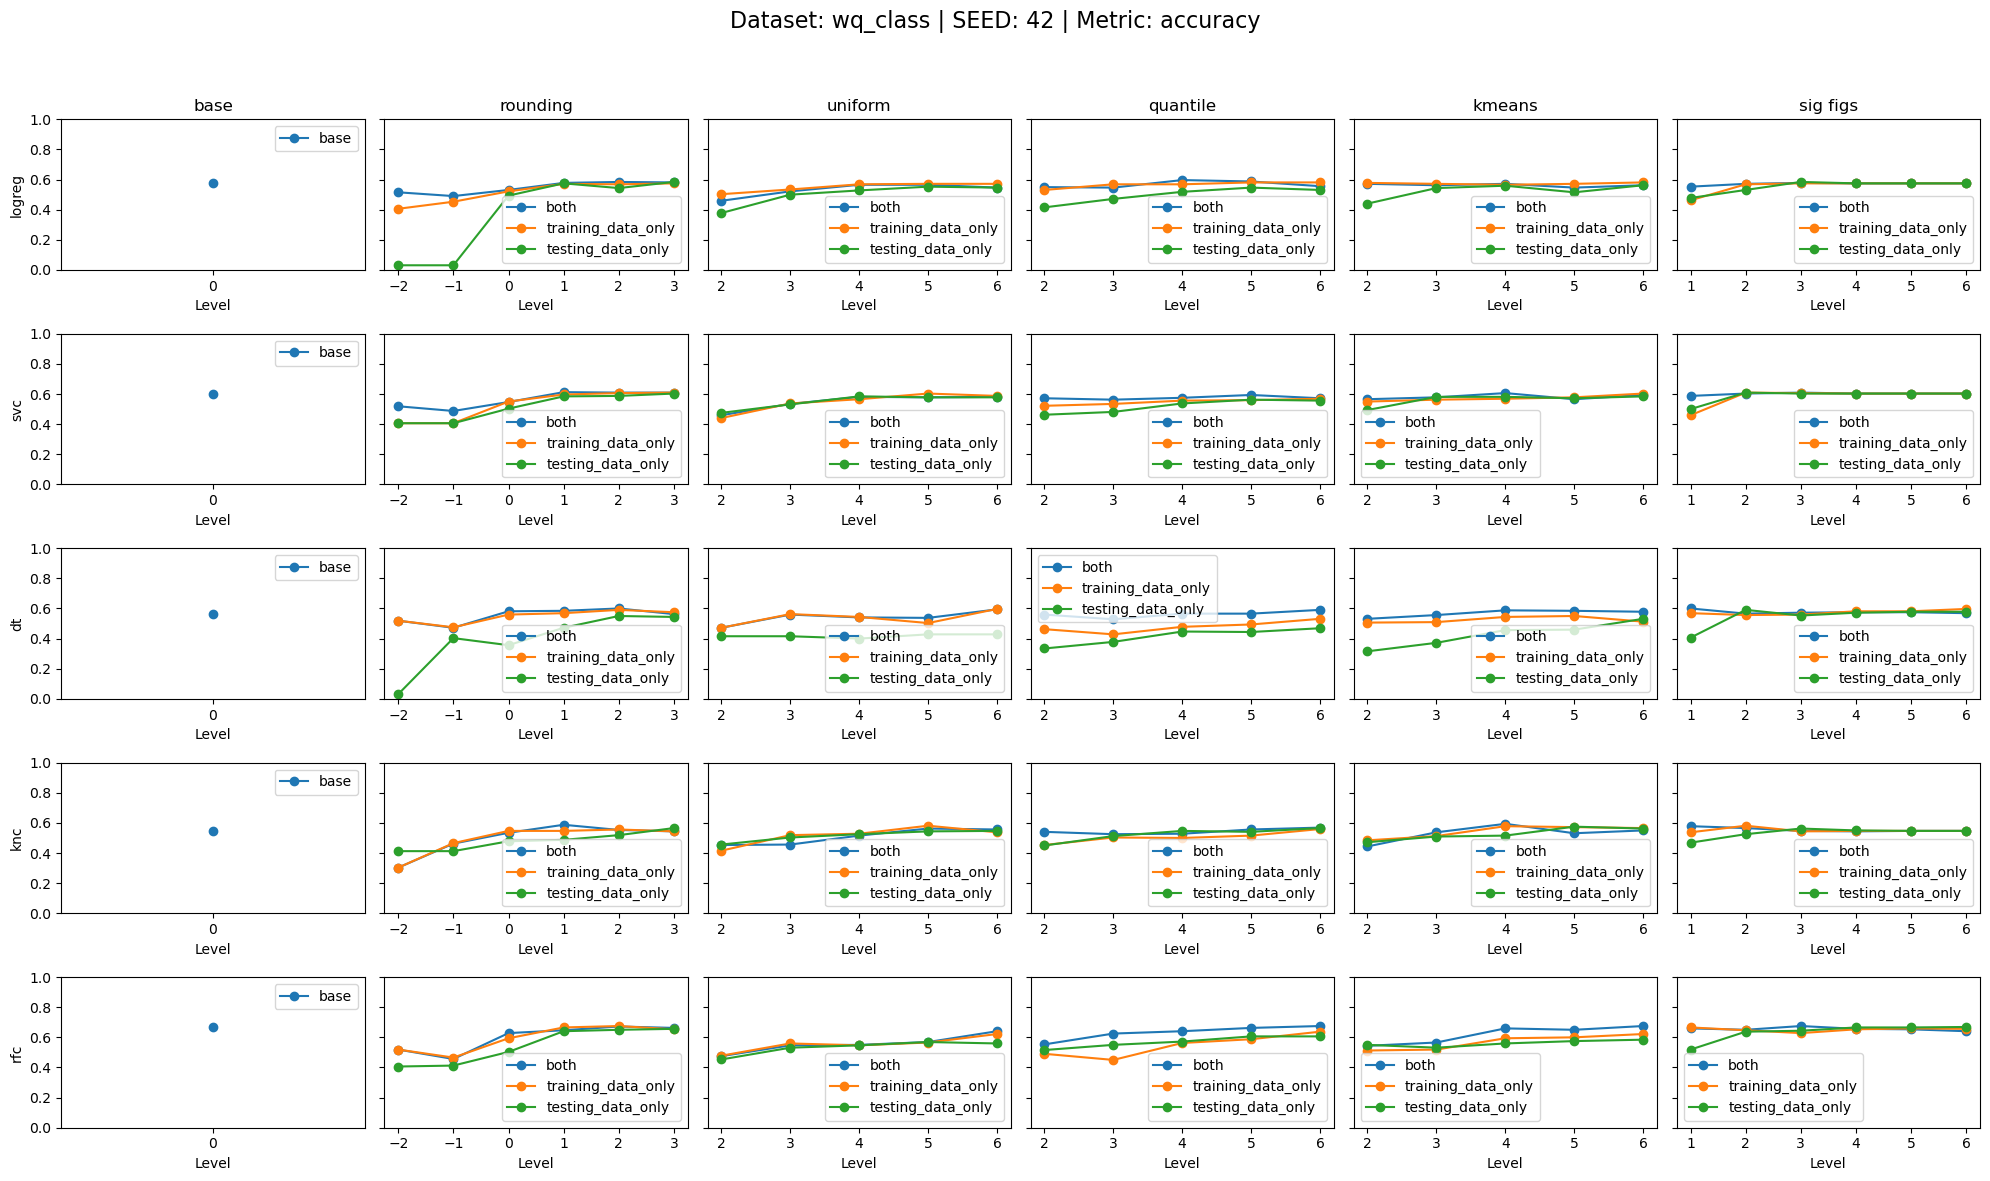

In [21]:
metric = "accuracy"   # change to 'accuracy', 'r2', 'mse', or 'mae'

datasets = results_df['dataset'].dropna().unique()
models = results_df['model'].dropna().unique()
methods = results_df['method'].dropna().unique()

for dataset in datasets:

    # filter once for this dataset
    df_d = results_df[
        (results_df['dataset'] == dataset) &
        (results_df[metric].notna())
    ]

    if df_d.empty:
        continue

    # decide y-limits based on metric
    if metric == 'accuracy':
        ymin, ymax = 0, 1

    elif metric == 'r2':
        data_min = df_d[metric].min()
        data_max = df_d[metric].max()
        print(data_min)

        y_range = data_max - data_min
        pad = 0.1 * y_range if y_range > 0 else 0.1

        ymin = data_min - pad
        print(ymin)
        # ymax = data_max + pad

        # optional: cap the top at 1 since R² usually doesn't exceed 1
        ymax = 1

    elif metric in ['mse', 'mae']:
        data_min = df_d[metric].min()
        data_max = df_d[metric].max()
        print(data_min,data_max)

        y_range = data_max - data_min
        pad = 0.1 * y_range if y_range > 0 else 0.1

        ymin = data_min - pad
        ymax = data_max + pad

    else:
        # fallback for any other metric
        data_min = df_d[metric].min()
        data_max = df_d[metric].max()

        y_range = data_max - data_min
        pad = 0.1 * y_range if y_range > 0 else 0.1

        ymin = data_min - pad
        ymax = data_max + pad

    fig, axes = plt.subplots(
        len(models),
        len(methods),
        figsize=(20, 12),
        sharey=True
    )

    axes = np.atleast_2d(axes)

    for i, model in enumerate(models):
        for j, method in enumerate(methods):

            ax = axes[i, j]

            subset = df_d[
                (df_d['model'] == model) &
                (df_d['method'] == method)
            ]

            if subset.empty:
                ax.set_visible(False)
                continue

            for mode in subset['mode'].dropna().unique():
                mode_data = subset[subset['mode'] == mode].sort_values('level')

                ax.plot(
                    mode_data['level'],
                    mode_data[metric],
                    marker='o',
                    label=mode
                )

            if i == 0:
                ax.set_title(method)
            if j == 0:
                ax.set_ylabel(model)

            ax.set_xlabel("Level")
            ax.set_xticks(sorted(subset['level'].dropna().unique()))
            ax.set_ylim(ymin, ymax)

            if metric == 'r2':
                ax.axhline(0, linestyle='--', linewidth=1)

            ax.legend()

    fig.suptitle(
        f"Dataset: {dataset} | SEED: {random_state} | Metric: {metric}",
        fontsize=16
    )

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

In [22]:
X_thing = np.array([[2.3],
              [5.1],
              [7.8],
              [1.2],
              [9.0],
              [4.5]])

kbd = KBinsDiscretizer(
    n_bins=3,
    encode='ordinal',      
    strategy='uniform'     
)

X_binned = kbd.fit_transform(X_thing)

print("Binned values:")
print(X_binned)

print("Bin edges:")
print(kbd.bin_edges_)
print(kbd.inverse_transform(kbd.fit_transform(X_thing)))

Binned values:
[[0.]
 [1.]
 [2.]
 [0.]
 [2.]
 [1.]]
Bin edges:
[array([1.2, 3.8, 6.4, 9. ])]
[[2.5]
 [5.1]
 [7.7]
 [2.5]
 [7.7]
 [5.1]]


In [23]:
print(os.environ.get("OMP_NUM_THREADS"))

16


In [24]:
splits["bc"]["X_train"].nunique()

radius_mean                381
texture_mean               392
perimeter_mean             424
area_mean                  431
smoothness_mean            393
compactness_mean           433
concavity_mean             441
concave points_mean        436
symmetry_mean              361
fractal_dimension_mean     413
radius_se                  436
texture_se                 417
perimeter_se               438
area_se                    421
smoothness_se              446
compactness_se             438
concavity_se               431
concave points_se          417
symmetry_se                409
fractal_dimension_se       435
radius_worst               378
texture_worst              411
perimeter_worst            418
area_worst                 438
smoothness_worst           351
compactness_worst          426
concavity_worst            437
concave points_worst       397
symmetry_worst             416
fractal_dimension_worst    432
dtype: int64

In [29]:
with pd.ExcelWriter("Project-Data.xlsx", engine="openpyxl", mode="a", if_sheet_exists="overlay") as writer:
    
    results_df.to_excel(writer, sheet_name="wq_1", startrow=1, header=False)